# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [ ]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  +1.9610  F =  +59.1376  |diff| = 2.8e-07
r = 1.12  U =  -0.9998  F =   +0.1440  |diff| = 1.9e-08
r = 1.50  U =  -0.3203  F =   -1.1580  |diff| = 2.6e-10
r = 2.00  U =  -0.0615  F =   -0.1816  |diff| = 4.0e-11
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -1.0


**Your turn.** Replace the potential by a Morse potential $U=(1-e^{-2(r-1)})^2-1$ and its derivative. Where is the force zero?

### SOLUTION 1

In [1]:
import numpy as np


U  = lambda r: (1 - np.exp(-2 * (r - 1)))**2 - 1
dU = lambda r: 4 * np.exp(-2 * (r - 1)) * (1 - np.exp(-2 * (r - 1)))

h = 1e-5

for r in (0.8, 1.0, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(
        f"r = {r:4.2f}  U = {U(r):+8.4f}  "
        f"F = {F_analytic:+9.4f}  "
        f"|diff| = {abs(F_analytic - F_numeric):.1e}"
    )

print("Force zero at r = 1.0, U(r) =", U(1.0))

r = 0.80  U =  -0.7581  F =   +2.9349  |diff| = 2.0e-09
r = 1.00  U =  -1.0000  F =   -0.0000  |diff| = 8.0e-10
r = 1.12  U =  -0.9545  F =   -0.6714  |diff| = 4.4e-10
r = 1.50  U =  -0.6004  F =   -0.9302  |diff| = 4.2e-11
r = 2.00  U =  -0.2524  F =   -0.4681  |diff| = 2.3e-11
Force zero at r = 1.0, U(r) = -1.0


---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

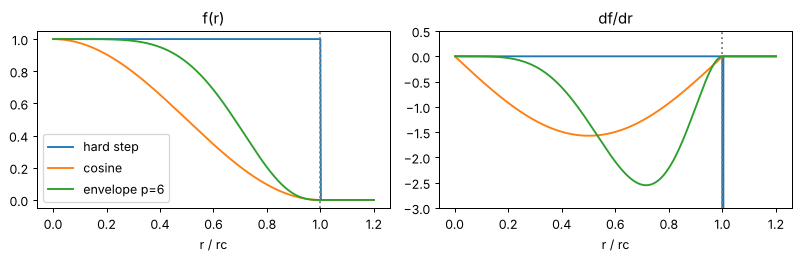

In [ ]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** The hard step's derivative is a spike (a delta function) at $r_c$. What would that mean for the force on an atom crossing the cutoff during MD?

# SOLUTION 2

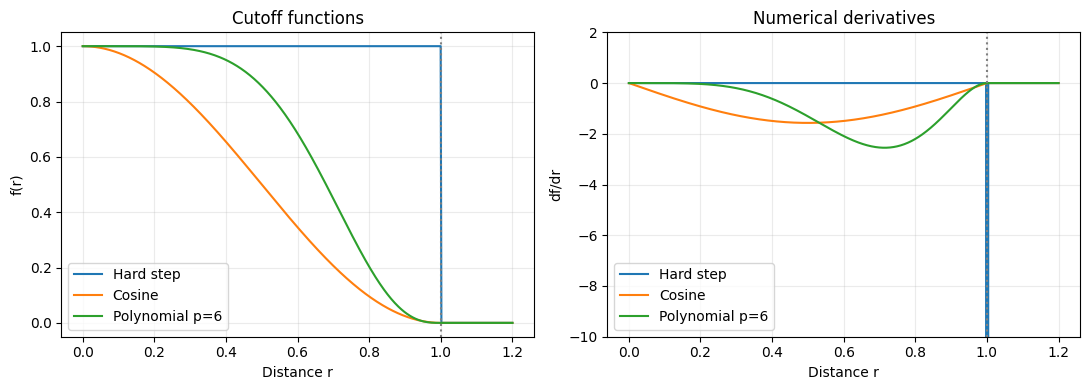

At the cutoff rc = 1.0
Hard step: discontinuous; derivative is impulse-like.
Cosine: function and first derivative approach zero.
Polynomial: inspect its value and slope at rc.


In [3]:

import numpy as np
import matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = r / rc
p = 6

# Cutoff functions
hard = (r < rc).astype(float)

cosine = np.where(
    r < rc,
    0.5 * (1 + np.cos(np.pi * x)),
    0.0
)

env = np.where(
    r < rc,
    1 - 28*x**p + 48*x**(p+1) - 21*x**(p+2),
    0.0
)

# Numerical derivatives
def derivative(f, r):
    return np.gradient(f, r)

dh = derivative(hard, r)
dc = derivative(cosine, r)
de = derivative(env, r)

# Plot cutoff functions and derivatives
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(r, hard, label="Hard step")
ax[0].plot(r, cosine, label="Cosine")
ax[0].plot(r, env, label="Polynomial p=6")
ax[0].set_title("Cutoff functions")
ax[0].set_ylabel("f(r)")
ax[0].legend()

ax[1].plot(r, dh, label="Hard step")
ax[1].plot(r, dc, label="Cosine")
ax[1].plot(r, de, label="Polynomial p=6")
ax[1].set_title("Numerical derivatives")
ax[1].set_ylabel("df/dr")
ax[1].set_ylim(-10, 2)
ax[1].legend()

for a in ax:
    a.axvline(rc, color="gray", linestyle=":")
    a.set_xlabel("Distance r")
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("At the cutoff rc =", rc)
print("Hard step: discontinuous; derivative is impulse-like.")
print("Cosine: function and first derivative approach zero.")
print("Polynomial: inspect its value and slope at rc.")


---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

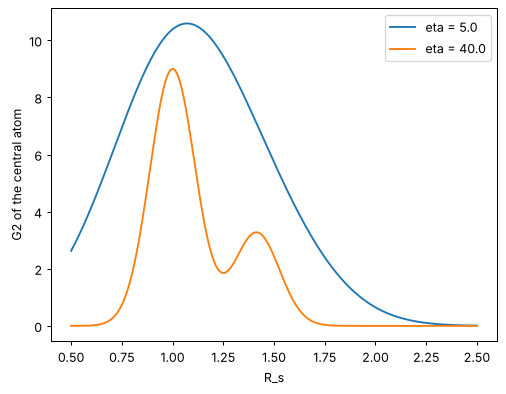

In [ ]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

**Your turn.** Remove the 6 second-shell atoms. Which peak disappears? With $\eta=5$, can you still tell the two shells apart?

# SOLUTION 3

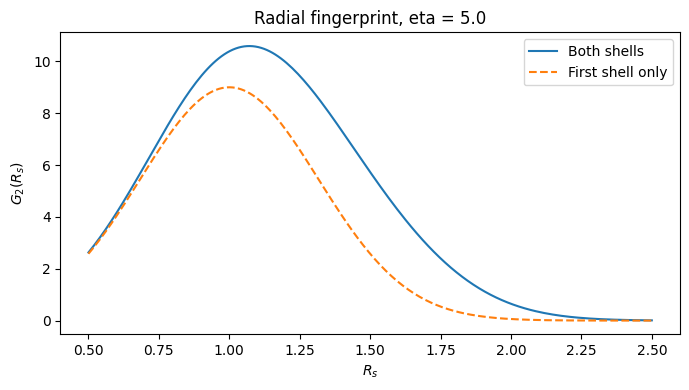

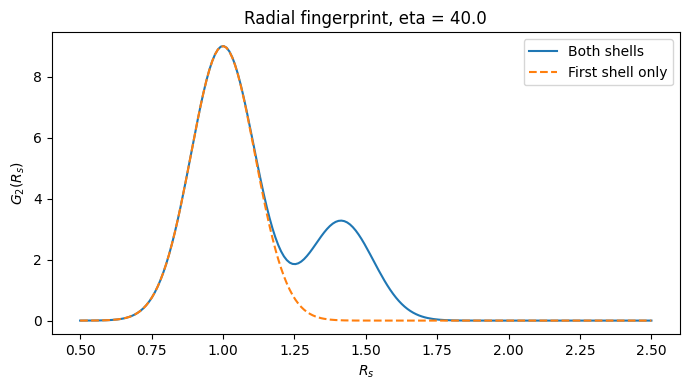

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fc = lambda r, rc: np.where(
    r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0
)

nn = np.array([
    [1,1,0], [1,-1,0], [-1,1,0], [-1,-1,0],
    [1,0,1], [1,0,-1], [-1,0,1], [-1,0,-1],
    [0,1,1], [0,1,-1], [0,-1,1], [0,-1,-1]
]) / np.sqrt(2)

nnn = np.array([
    [1,0,0], [-1,0,0], [0,1,0],
    [0,-1,0], [0,0,1], [0,0,-1]
]) * np.sqrt(2)

# All 18 neighbours
R_all = np.vstack([[0, 0, 0], nn, nnn])

# Remove the 6 second-shell atoms
R_first = np.vstack([[0, 0, 0], nn])

r_all = np.linalg.norm(R_all[1:] - R_all[0], axis=1)
r_first = np.linalg.norm(R_first[1:] - R_first[0], axis=1)

Rs = np.linspace(0.5, 2.5, 200)

for eta in (5.0, 40.0):
    G2_all = [
        np.sum(np.exp(-eta * (r_all - s)**2) * fc(r_all, 3.0))
        for s in Rs
    ]
    G2_first = [
        np.sum(np.exp(-eta * (r_first - s)**2) * fc(r_first, 3.0))
        for s in Rs
    ]

    plt.figure(figsize=(7, 4))
    plt.plot(Rs, G2_all, label="Both shells")
    plt.plot(Rs, G2_first, "--", label="First shell only")
    plt.title(f"Radial fingerprint, eta = {eta}")
    plt.xlabel(r"$R_s$")
    plt.ylabel(r"$G_2(R_s)$")
    plt.legend()
    plt.tight_layout()
    plt.show()

Expected observation: η=5 gives broad peaks with more overlap, while η=40
η=40 gives narrower peaks and better radial resolution. Removing the second shell eliminates its contribution near Rs=1.414



---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

recovered angle: 104.5 deg


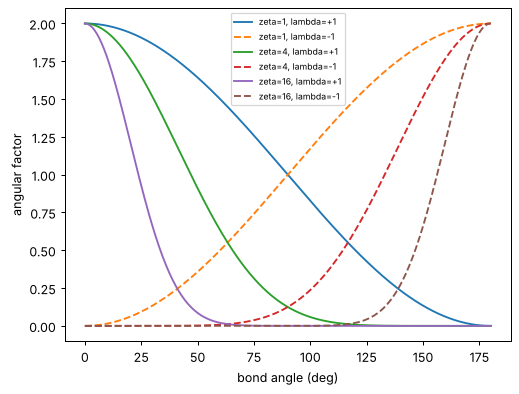

In [ ]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

**Your turn.** Which $\zeta$ would you use to distinguish $100^\circ$ from $110^\circ$? Compute $(1-\cos\theta)^\zeta$ at both angles for $\zeta=1$ and $\zeta=16$ and compare the relative difference.

# SOLUTION 4

In [5]:
import numpy as np

angles = [100, 110]

for zeta in [1, 16]:
    values = [
        (1 - np.cos(np.deg2rad(theta)))**zeta
        for theta in angles
    ]

    relative_diff = (values[1] - values[0]) / values[0] * 100

    print(f"zeta = {zeta}")
    print(f"  100 degrees: {values[0]:.6f}")
    print(f"  110 degrees: {values[1]:.6f}")
    print(f"  Relative difference: {relative_diff:.2f}%")

zeta = 1
  100 degrees: 1.173648
  110 degrees: 1.342020
  Relative difference: 14.35%
zeta = 16
  100 degrees: 12.960055
  110 degrees: 110.699218
  Relative difference: 754.16%



ζ=16 provides much greater angular contrast between the two angles than ζ=1
ζ=1. In practice, very high ζ,
ζ can also make descriptors more sensitive to noise and numerical errors.